<a href="https://colab.research.google.com/github/jojojojo-jo/LRP_analysis_resnet/blob/main/resnet18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#0. Import

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F

from PIL import Image

import os
import numpy as np

import torchvision
from torchvision import models, transforms

#import torchinfo.summary
try:
  from torchinfo import summary
except:
  print("[INFO] Couldn't find torchinfo... installing it")
  !pip install -q torchinfo
  from torchinfo import summary

#import helper functions
try:
  from going_modular.going_modular import data_setup, engine
except:
  print(f"[INFO] Couldn't find going_modular scripts... downloading from GitHub")
  !git clone https://github.com/mrdbourke/pytorch-deep-learning
  !mv pytorch-deep-learning/going_modular .
  !rm -rf pytorch-deep-learning
  from going_modular.going_modular import data_setup, engine

[INFO] Couldn't find torchinfo... installing it
[INFO] Couldn't find going_modular scripts... downloading from GitHub
Cloning into 'pytorch-deep-learning'...
remote: Enumerating objects: 4410, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 4410 (delta 5), reused 2 (delta 2), pack-reused 4399 (from 2)
Receiving objects: 100% (4410/4410), 764.18 MiB | 40.88 MiB/s, done.
Resolving deltas: 100% (2661/2661), done.
Updating files: 100% (248/248), done.


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

#1. Get data

In [ ]:
import os
import zipfile

from pathlib import Path

import requests

data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi_20_percent"

if image_path.is_dir():
  print(f"{image_path} directory exists")
else:
  print(f"Did not find {image_path} directory, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)

  with open(data_path / "pizza_steak_sushi_20_percent.zip", "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")
    print("Downloading data...")
    f.write(request.content)

  with zipfile.ZipFile(data_path / "pizza_steak_sushi_20_percent.zip", "r") as zip_ref:
    print("Unzipping data...")
    zip_ref.extractall(image_path)

  os.remove(data_path / "pizza_steak_sushi_20_percent.zip")

Did not find data/pizza_steak_sushi_20_percent directory, creating one...
Unzipping data...


In [ ]:
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi_20_percent/train'),
 PosixPath('data/pizza_steak_sushi_20_percent/test'))

#2. Create Dataset and DataLoaders

In [ ]:
weights = torchvision.models.ResNet18_Weights.DEFAULT
auto_transforms = weights.transforms()
print(f"Automatically created transforms: {auto_transforms}")

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=auto_transforms,
                                                                               batch_size=64)
train_dataloader, test_dataloader, class_names

Automatically created transforms: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


(<torch.utils.data.dataloader.DataLoader at 0x7996fac39d60>,
 ['pizza', 'steak', 'sushi'])

#3. Tune model

In [ ]:
model = torchvision.models.resnet18(weights=weights).to(device)
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
summary(model=model,
        input_size=(32, 3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
ResNet (ResNet)                          [32, 3, 224, 224]    [32, 1000]           --                   True
├─Conv2d (conv1)                         [32, 3, 224, 224]    [32, 64, 112, 112]   9,408                True
├─BatchNorm2d (bn1)                      [32, 64, 112, 112]   [32, 64, 112, 112]   128                  True
├─ReLU (relu)                            [32, 64, 112, 112]   [32, 64, 112, 112]   --                   --
├─MaxPool2d (maxpool)                    [32, 64, 112, 112]   [32, 64, 56, 56]     --                   --
├─Sequential (layer1)                    [32, 64, 56, 56]     [32, 64, 56, 56]     --                   True
│    └─BasicBlock (0)                    [32, 64, 56, 56]     [32, 64, 56, 56]     --                   True
│    │    └─Conv2d (conv1)               [32, 64, 56, 56]     [32, 64, 56, 56]     36,864               True
│    │    └─BatchN

In [ ]:
for param in model.parameters():
    param.requires_grad = False

torch.manual_seed(42)
model.fc = nn.Linear(in_features=512, out_features=len(class_names), bias=True)

In [ ]:
model=model.to(device)

summary(model=model,
        input_size=(32, 3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
ResNet (ResNet)                          [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Conv2d (conv1)                         [32, 3, 224, 224]    [32, 64, 112, 112]   (9,408)              False
├─BatchNorm2d (bn1)                      [32, 64, 112, 112]   [32, 64, 112, 112]   (128)                False
├─ReLU (relu)                            [32, 64, 112, 112]   [32, 64, 112, 112]   --                   --
├─MaxPool2d (maxpool)                    [32, 64, 112, 112]   [32, 64, 56, 56]     --                   --
├─Sequential (layer1)                    [32, 64, 56, 56]     [32, 64, 56, 56]     --                   False
│    └─BasicBlock (0)                    [32, 64, 56, 56]     [32, 64, 56, 56]     --                   False
│    │    └─Conv2d (conv1)               [32, 64, 56, 56]     [32, 64, 56, 56]     (36,864)             False
│    │    

#4. Train model

In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=0.01)

scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=4)

In [ ]:
def train_step(model, dataloader, loss_fn, optimizer, device):
    model.train()
    train_loss, train_acc = 0, 0
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)

    return train_loss / len(dataloader), train_acc / len(dataloader)

def test_step(model, dataloader, loss_fn, device):
    model.eval()
    test_loss, test_acc = 0, 0
    with torch.inference_mode():
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
            test_pred = model(X)
            loss = loss_fn(test_pred, y)
            test_loss += loss.item()

            test_pred_labels = test_pred.argmax(dim=1)
            test_acc += (test_pred_labels == y).sum().item() / len(test_pred)

    return test_loss / len(dataloader), test_acc / len(dataloader)

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

from tqdm.auto import tqdm
from timeit import default_timer as timer
start_time = timer()

epochs = 80
results = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}
best_acc = 0

for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, device)
    test_loss, test_acc = test_step(model, test_dataloader, loss_fn, device)

    old_lr = optimizer.param_groups[0]['lr']

    # CRITICAL: Step based on test_loss
    scheduler.step(test_loss)

    current_lr = optimizer.param_groups[0]['lr']
    if current_lr < old_lr:
        print(f"📉 Learning rate decayed from {old_lr} to {current_lr}")

    results["train_loss"].append(train_loss)
    results["test_loss"].append(test_loss)
    results["train_acc"].append(train_acc)
    results["test_acc"].append(test_acc)

    print(f"Epoch: {epoch+1} | Train Loss: {train_loss:.4f} | Train Acc: {(train_acc*100):.2f}% | Test Loss: | {test_loss:.4f} | Test Acc: {(test_acc*100):.2f}%")

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(model.state_dict(), 'models/best_model.pth')
        print(f"New best model saved with {test_acc:.4f} accuracy!")

end_time = timer()
print(f"[INFO] Total training time: {end_time - start_time:.3f} seconds")

  0%|          | 0/80 [00:00<?, ?it/s]

Epoch: 1 | Train Loss: 0.9853 | Train Acc: 52.15% | Test Loss: | 0.8752 | Test Acc: 65.96%
New best model saved with 0.6596 accuracy!
Epoch: 2 | Train Loss: 0.8905 | Train Acc: 62.89% | Test Loss: | 0.7825 | Test Acc: 75.24%
New best model saved with 0.7524 accuracy!
Epoch: 3 | Train Loss: 0.7883 | Train Acc: 77.15% | Test Loss: | 0.7162 | Test Acc: 77.37%
New best model saved with 0.7737 accuracy!
Epoch: 4 | Train Loss: 0.7042 | Train Acc: 76.76% | Test Loss: | 0.6436 | Test Acc: 83.48%
New best model saved with 0.8348 accuracy!
Epoch: 5 | Train Loss: 0.6502 | Train Acc: 79.69% | Test Loss: | 0.6172 | Test Acc: 80.49%
Epoch: 6 | Train Loss: 0.6540 | Train Acc: 82.23% | Test Loss: | 0.5595 | Test Acc: 85.04%
New best model saved with 0.8504 accuracy!
Epoch: 7 | Train Loss: 0.6165 | Train Acc: 83.59% | Test Loss: | 0.5187 | Test Acc: 87.64%
New best model saved with 0.8764 accuracy!
Epoch: 8 | Train Loss: 0.5748 | Train Acc: 78.12% | Test Loss: | 0.5045 | Test Acc: 87.17%
Epoch: 9 | Tra

#5. Plot loss curves

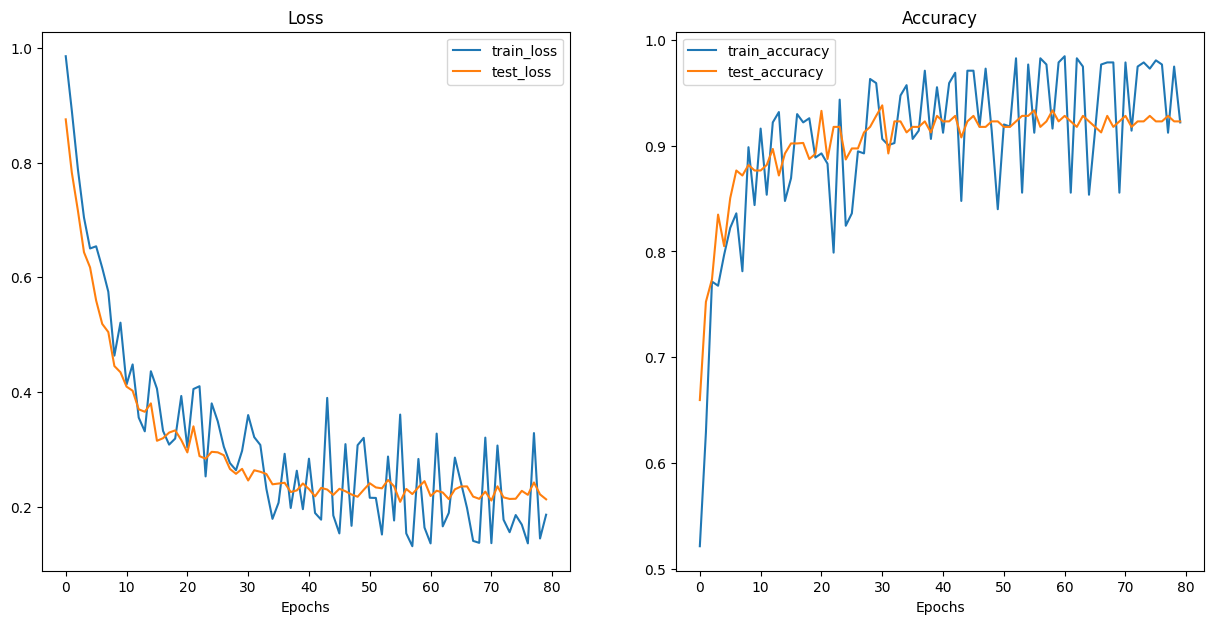

In [ ]:
import matplotlib.pyplot as plt

def plot_loss_curves(results):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """
    loss = results["train_loss"]
    test_loss = results["test_loss"]

    accuracy = results["train_acc"]
    test_accuracy = results["test_acc"]

    epochs = range(len(results["train_loss"]))

    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label="train_loss")
    plt.plot(epochs, test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label="train_accuracy")
    plt.plot(epochs, test_accuracy, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

plot_loss_curves(results)

#6. Check random sample

In [ ]:
img_batch, label_batch = next(iter(train_dataloader))
sample_img, sample_label = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Image shape: {sample_img.shape} -> batch_size, color_channels, height, width\n")

model.eval()
with torch.inference_mode():
    output = model(sample_img.to(device))
    output_pred = torch.softmax(output, dim=1)
    prediction_score, pred_label_idx = torch.topk(output, 1)

    pred_label_idx.squeeze_()
    pred_label = torch.argmax(torch.softmax(output, dim=1), dim=1)

print(f"Output logits:\n{output}\n")
print(f"Output prediction probabilities:\n{output_pred}\n")
print(f"Output prediction label:\n{pred_label}\n")
print(f"Actual label:\n{sample_label}")
print(f"Predicted: {pred_label} ({prediction_score.squeeze().item()})")

Image shape: torch.Size([1, 3, 224, 224]) -> batch_size, color_channels, height, width

Output logits:
tensor([[ 1.7743, -2.4158, -1.4967]], device='cuda:0')

Output prediction probabilities:
tensor([[0.9496, 0.0144, 0.0361]], device='cuda:0')

Output prediction label:
tensor([0], device='cuda:0')

Actual label:
0
Predicted: tensor([0], device='cuda:0') (1.7742921113967896)


#7. Save model

In [ ]:
from google.colab import drive
drive.mount('/content/drive' , force_remount=True)

Mounted at /content/drive


In [ ]:
import os

if os.path.exists('/content/drive/MyDrive'):
    print("Drive is mounted successfully!")
else:
    print("Drive is NOT mounted. Please run the mount command again.")

Drive is mounted successfully!


In [ ]:
import shutil

source_path = '/content/models/best_model_plateau.pth'
destination_path = '/content/drive/MyDrive/study/Project'

shutil.copy(source_path, destination_path)

print("Best model saved to drive")

Best model saved to drive
